# 03 · Models — Vehicle Type (Classification)
Same 5 stratified folds (seed 42) for every model. Each model is scored on clean CV and with Gaussian noise (k × feature std) added to the validation features for k = 0.1, 0.2, 0.3.

**Selection score = mean accuracy over k ∈ {0, 0.1, 0.2, 0.3}.**

## Setup
Make `src/` importable and load the shared config (seed, paths).

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

# Make `src` importable: repo root locally, or an uploaded Kaggle dataset containing src/
for p in [Path.cwd(), *Path.cwd().parents, *(f.parent.parent for f in Path("/kaggle/input").glob("**/src/config.py"))]:
    if (p / "src" / "config.py").exists():
        sys.path.insert(0, str(p.resolve()))
        break

from src import config

Load the clean data.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from src import evaluate
from src.classification import preprocess as pp
from src.classification.models import NoiseAugmented, NoiseAwareLDA

warnings.filterwarnings("ignore", category=FutureWarning)
TASK = "classification"
FIG_DIR = config.results_dir(TASK) / "figures"
KS = [0, 0.1, 0.2, 0.3]
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)

X, y, X_test, test_ids, sample_sub = pp.load_clean()
print("X", X.shape, "| X_test", X_test.shape)

X (7500, 20) | X_test (2500, 20)


Helpers: score a model clean and with noise, log it, and grid-search by noise-averaged accuracy.

In [3]:
curves = {}  # model name -> accuracy at each k, for the final comparison plot

def scores(model):
    clean = evaluate.cross_validate(model, X, y, TASK, "", log=False)
    noisy = evaluate.noise_curve(model, X, y, TASK, KS)["mean"]
    return clean, noisy

def run(name, model, params=None, notes=""):
    clean, noisy = scores(model)
    extra = {f"acc_k{k}": noisy[k] for k in KS[1:]} | {"acc_noise_mean": noisy.mean()}
    evaluate.cross_validate(model, X, y, TASK, name, params=params, notes=notes, extra=extra)
    curves[name] = noisy
    print(f"{name:26s} clean {clean.accuracy.mean():.4f} ± {clean.accuracy.std():.4f} | train {clean.train_accuracy.mean():.4f}"
          f" | k=0.3 {noisy[0.3]:.4f} | noise-avg {noisy.mean():.4f}")

def search(name, make_model, grid, notes=""):
    rows = []
    for params in grid:
        clean, noisy = scores(make_model(**params))
        rows.append({**params, "clean": clean.accuracy.mean(), "train": clean.train_accuracy.mean(),
                     **{f"k={k}": noisy[k] for k in KS[1:]}, "noise-avg": noisy.mean()})
    table = pd.DataFrame(rows)
    best = grid[int(table["noise-avg"].idxmax())]
    display(table.sort_values("noise-avg", ascending=False).round(4))
    print("best by noise-averaged accuracy:", best)
    run(name, make_model(**best), params=best, notes=(notes + f" | best of {len(grid)} by noise-avg").strip(" |"))
    return best

## 0 · Majority class (baseline)

In [4]:
run("0_majority", DummyClassifier(strategy="most_frequent"))
path, _ = evaluate.make_submission(DummyClassifier(strategy="most_frequent"), X, y, X_test, test_ids, sample_sub, TASK, "0_majority", date="2026-10-12")
print("saved:", path.name)

0_majority                 clean 0.3385 ± 0.0003 | train 0.3385 | k=0.3 0.3385 | noise-avg 0.3385
saved: 2026-10-12_0_majority.csv


- Accuracy 0.3385; public score 0.348.

## 1 · Gaussian Naive Bayes

In [5]:
run("1_naive_bayes", GaussianNB(), notes="Gaussian NB, independence assumption")

1_naive_bayes              clean 0.8465 ± 0.0075 | train 0.8467 | k=0.3 0.8417 | noise-avg 0.8444


- Clean 0.8465: correlated features break the independence assumption.

## 2 · LDA and QDA

In [6]:
run("2a_lda", LinearDiscriminantAnalysis(), notes="shared full covariance -> linear boundary")
_ = search("2b_qda", lambda reg_param: QuadraticDiscriminantAnalysis(reg_param=reg_param),
           [{"reg_param": r} for r in [0, 0.05, 0.1, 0.3]], notes="per-class covariance -> quadratic boundary")

2a_lda                     clean 0.8924 ± 0.0036 | train 0.8943 | k=0.3 0.8720 | noise-avg 0.8847


,reg_param,clean,train,k=0.1,k=0.2,k=0.3,noise-avg
2,0.10,0.8845,0.8916,0.8807,0.8723,0.8592,0.8742
1,0.05,0.8848,0.8927,0.8805,0.8728,0.8573,0.8739
3,0.30,0.8839,0.8890,0.8781,0.8716,0.8571,0.8727
0,0.00,0.8848,0.8929,0.8795,0.8667,0.8504,0.8703


best by noise-averaged accuracy: {'reg_param': 0.1}


2b_qda                     clean 0.8845 ± 0.0062 | train 0.8916 | k=0.3 0.8592 | noise-avg 0.8742


- LDA 0.8924 clean; QDA (reg_param 0.1) is worse at 0.8845.

## 3 · Logistic regression, L2 (tune C)

In [7]:
def logistic(C, penalty="l2"):
    # l1_ratio = 1 means pure L1, 0 pure L2 (sklearn 1.9 replaced the old `penalty=` argument with this)
    l1 = penalty == "l1"
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, l1_ratio=1.0 if l1 else 0.0, max_iter=5000,
                                                              solver="saga" if l1 else "lbfgs"))

lr_best = search("3_logistic_l2", logistic, [{"C": c} for c in [0.001, 0.01, 0.1, 1, 10]], notes="standardised, multinomial")

,C,clean,train,k=0.1,k=0.2,k=0.3,noise-avg
2,0.100,0.8941,0.8960,0.8913,0.8859,0.8772,0.8871
4,10.000,0.8940,0.8951,0.8915,0.8861,0.8728,0.8861
3,1.000,0.8941,0.8954,0.8917,0.8856,0.8727,0.8860
1,0.010,0.8909,0.8914,0.8875,0.8835,0.8769,0.8847
0,0.001,0.8695,0.8693,0.8684,0.8665,0.8615,0.8665


best by noise-averaged accuracy: {'C': 0.1}


3_logistic_l2              clean 0.8941 ± 0.0060 | train 0.8960 | k=0.3 0.8772 | noise-avg 0.8871


- Best C = 0.1: clean 0.8941, noise-averaged 0.8871.

Confusion matrix and largest weights.

In [8]:
oof = evaluate.oof_predict(logistic(**lr_best), X, y, TASK).astype(int)
names = [pp.CLASS_NAMES[i] for i in range(3)]
display(pd.DataFrame(confusion_matrix(y, oof), index=[f"true {n}" for n in names], columns=[f"pred {n}" for n in names]))

coefs = pd.DataFrame(logistic(**lr_best).fit(X, y)[-1].coef_.T, index=X.columns, columns=names)
display(coefs.loc[coefs.abs().max(axis=1).sort_values(ascending=False).index].head(8).round(2))

,pred Sedan,pred SUV,pred Sports Car
true Sedan,2146,221,172
true SUV,214,2264,12
true Sports Car,164,11,2296


,Sedan,SUV,Sports Car
acceleration_0_100_kmh_s,0.59,0.88,-1.48
wheelbase_mm,-0.23,1.27,-1.04
vehicle_length_mm,-0.23,0.83,-0.59
vehicle_width_mm,-0.28,0.69,-0.41
battery_capacity_kwh,-0.00,-0.66,0.66
engine_displacement_l,-0.19,-0.37,0.56
vehicle_weight_kg,-0.09,0.54,-0.44
horsepower_hp,-0.14,-0.40,0.53


- Almost all errors involve Sedan.

## 4 · Logistic regression, L1 (tune C)

In [9]:
l1_best = search("4_logistic_l1", lambda C: logistic(C, "l1"), [{"C": c} for c in [0.01, 0.03, 0.1, 1]], notes="standardised, L1")
for C in [0.01, 0.03, 0.1]:
    w = logistic(C, "l1").fit(X, y)[-1].coef_
    used = (np.abs(w).max(axis=0) > 1e-6)
    print(f"C={C}: uses {used.sum()} of 20 features; dropped: {list(X.columns[~used])}")

,C,clean,train,k=0.1,k=0.2,k=0.3,noise-avg
3,1.00,0.8937,0.8956,0.8908,0.8857,0.8728,0.8858
2,0.10,0.8927,0.8943,0.8896,0.8840,0.8721,0.8846
1,0.03,0.8899,0.8897,0.8853,0.8784,0.8672,0.8802
0,0.01,0.8819,0.8829,0.8799,0.8720,0.8620,0.8739


best by noise-averaged accuracy: {'C': 1}


4_logistic_l1              clean 0.8937 ± 0.0059 | train 0.8956 | k=0.3 0.8728 | noise-avg 0.8858
C=0.01: uses 11 of 20 features; dropped: ['engine_displacement_l', 'horsepower_hp', 'fuel_tank_capacity_l', 'city_fuel_efficiency_kmpl', 'engine_cylinders', 'torque_nm', 'ground_clearance_mm', 'cargo_capacity_l', 'tire_width_mm']
C=0.03: uses 16 of 20 features; dropped: ['engine_displacement_l', 'engine_cylinders', 'cargo_capacity_l', 'tire_width_mm']


C=0.1: uses 20 of 20 features; dropped: []


- Best C = 1 keeps all features; dropping features hurts under noise.

## 5 · Logistic regression on degree-2 features

In [10]:
def poly_logistic(C):
    return make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(),
                         LogisticRegression(C=C, max_iter=5000))

_ = search("5_logistic_poly2", poly_logistic, [{"C": c} for c in [0.003, 0.01, 0.1]], notes="degree-2 features, L2")

,C,clean,train,k=0.1,k=0.2,k=0.3,noise-avg
1,0.010,0.8893,0.8950,0.8875,0.8824,0.8749,0.8835
0,0.003,0.8853,0.8895,0.8832,0.8791,0.8725,0.8800
2,0.100,0.8895,0.9040,0.8860,0.8780,0.8659,0.8798


best by noise-averaged accuracy: {'C': 0.01}


5_logistic_poly2           clean 0.8893 ± 0.0057 | train 0.8950 | k=0.3 0.8749 | noise-avg 0.8835


- Clean 0.8893: no gain, the boundary is linear.

## 6 · Decision trees (full and pruned)

In [11]:
run("6a_tree_full", DecisionTreeClassifier(random_state=config.SEED), notes="unpruned")
tree_best = search("6b_tree_pruned",
                   lambda max_depth, min_samples_leaf: DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                                                              random_state=config.SEED),
                   [{"max_depth": d, "min_samples_leaf": l} for d in [4, 6, 8, 12] for l in [10, 50]])

6a_tree_full               clean 0.8241 ± 0.0073 | train 1.0000 | k=0.3 0.7753 | noise-avg 0.8044


,max_depth,min_samples_leaf,clean,train,k=0.1,k=0.2,k=0.3,noise-avg
2,6,10,0.8607,0.8908,0.8575,0.8449,0.8281,0.8478
5,8,50,0.8596,0.8794,0.8575,0.8460,0.8281,0.8478
7,12,50,0.8596,0.8794,0.8575,0.8460,0.8281,0.8478
3,6,50,0.8599,0.8788,0.8569,0.8449,0.8279,0.8474
4,8,10,0.8568,0.9070,0.8517,0.8392,0.8195,0.8418
0,4,10,0.8545,0.8673,0.8503,0.8357,0.8185,0.8398
1,4,50,0.8521,0.8650,0.8475,0.8325,0.8163,0.8371
6,12,10,0.8479,0.9161,0.8448,0.8317,0.8137,0.8345


best by noise-averaged accuracy: {'max_depth': 6, 'min_samples_leaf': 10}


6b_tree_pruned             clean 0.8607 ± 0.0048 | train 0.8908 | k=0.3 0.8281 | noise-avg 0.8478


- Full tree 0.8241 clean, 0.7753 at k = 0.3. Pruned (depth 6, leaf ≥ 10): 0.8607.

## 7 · Random Forest and XGBoost

In [12]:
def forest(min_samples_leaf):
    return RandomForestClassifier(n_estimators=500, max_features="sqrt", min_samples_leaf=min_samples_leaf,
                                  n_jobs=-1, random_state=config.SEED)

def boost(max_depth):
    return XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=max_depth, subsample=0.8,
                         colsample_bytree=0.6, random_state=config.SEED, n_jobs=-1)

rf_best = search("7a_random_forest", forest, [{"min_samples_leaf": l} for l in [1, 5, 20]], notes="500 trees, sqrt features")
xgb_best = search("7b_xgboost", boost, [{"max_depth": d} for d in [2, 4]], notes="600 trees, lr 0.03")

,min_samples_leaf,clean,train,k=0.1,k=0.2,k=0.3,noise-avg
0,1,0.8828,1.0000,0.8804,0.8769,0.8697,0.8775
1,5,0.8819,0.9458,0.8799,0.8764,0.8669,0.8763
2,20,0.8784,0.9008,0.8769,0.8735,0.8653,0.8735


best by noise-averaged accuracy: {'min_samples_leaf': 1}


7a_random_forest           clean 0.8828 ± 0.0038 | train 1.0000 | k=0.3 0.8697 | noise-avg 0.8775


,max_depth,clean,train,k=0.1,k=0.2,k=0.3,noise-avg
0,2,0.8880,0.9087,0.8881,0.8805,0.8673,0.8810
1,4,0.8848,0.9595,0.8857,0.8817,0.8708,0.8808


best by noise-averaged accuracy: {'max_depth': 2}


7b_xgboost                 clean 0.8880 ± 0.0083 | train 0.9087 | k=0.3 0.8673 | noise-avg 0.8810


- Random Forest 0.8828, XGBoost (depth 2) 0.8880: below the linear models.

## 8 · Training for noise
- 8a: logistic regression trained on the data + 4 noisy copies.
- 8b: noise-aware LDA (covariance Σ + diag((k·std)²)).

In [13]:
aug_best = search("8a_logistic_noise_aug", lambda k: NoiseAugmented(logistic(**lr_best), k=k),
                  [{"k": k} for k in [0.1, 0.2, 0.3]], notes=f"logistic C={lr_best['C']} + 4 noisy copies")
nlda_best = search("8b_noise_aware_lda", lambda k: NoiseAwareLDA(k=k), [{"k": k} for k in [0.1, 0.2, 0.3]],
                   notes="LDA with covariance + diag((k*std)^2)")

,k,clean,train,k=0.1,k=0.2,k=0.3,noise-avg
1,0.2,0.8957,0.8963,0.8931,0.8847,0.8765,0.8875
2,0.3,0.8951,0.8954,0.8912,0.8855,0.8775,0.8873
0,0.1,0.8936,0.8959,0.8928,0.8856,0.8741,0.8865


best by noise-averaged accuracy: {'k': 0.2}


8a_logistic_noise_aug      clean 0.8957 ± 0.0067 | train 0.8963 | k=0.3 0.8765 | noise-avg 0.8875


,k,clean,train,k=0.1,k=0.2,k=0.3,noise-avg
1,0.2,0.8933,0.8943,0.8908,0.8861,0.8772,0.8869
2,0.3,0.8939,0.8946,0.8897,0.8855,0.8771,0.8865
0,0.1,0.8921,0.8942,0.8908,0.8848,0.8727,0.8851


best by noise-averaged accuracy: {'k': 0.2}


8b_noise_aware_lda         clean 0.8933 ± 0.0068 | train 0.8943 | k=0.3 0.8772 | noise-avg 0.8869


- 8a noise-averaged 0.8875 (best), 8b 0.8869; both insensitive to the assumed k.

## 9 · Soft-voting ensemble

In [14]:
run("9_soft_vote", VotingClassifier([("logistic", logistic(**lr_best)), ("nlda", NoiseAwareLDA(**nlda_best)),
                                      ("forest", forest(**rf_best)), ("xgb", boost(**xgb_best))], voting="soft"),
    notes="equal-weight average of class probabilities")

9_soft_vote                clean 0.8921 ± 0.0075 | train 0.9275 | k=0.3 0.8759 | noise-avg 0.8851


- 0.8851: below its best members.

## Comparison

,model,params,accuracy_mean,accuracy_std,train_accuracy_mean,acc_k0.1,acc_k0.2,acc_k0.3,acc_noise_mean,public_lb
0,8a_logistic_noise_aug,"{""k"": 0.2}",0.8957,0.0067,0.8963,0.8931,0.8847,0.8765,0.8875,0.900
1,3_logistic_l2,"{""C"": 0.1}",0.8941,0.0060,0.8960,0.8913,0.8859,0.8772,0.8871,NaN
2,8b_noise_aware_lda,"{""k"": 0.2}",0.8933,0.0068,0.8943,0.8908,0.8861,0.8772,0.8869,0.902
3,4_logistic_l1,"{""C"": 1}",0.8937,0.0059,0.8956,0.8908,0.8857,0.8728,0.8858,NaN
4,9_soft_vote,{},0.8921,0.0075,0.9275,0.8892,0.8831,0.8759,0.8851,NaN
5,2a_lda,{},0.8924,0.0036,0.8943,0.8908,0.8836,0.8720,0.8847,NaN
6,5_logistic_poly2,"{""C"": 0.01}",0.8893,0.0057,0.8950,0.8875,0.8824,0.8749,0.8835,NaN
7,7b_xgboost,"{""max_depth"": 2}",0.8880,0.0083,0.9087,0.8881,0.8805,0.8673,0.8810,NaN
8,7a_random_forest,"{""min_samples_leaf"": 1}",0.8828,0.0038,1.0000,0.8804,0.8769,0.8697,0.8775,NaN
9,2b_qda,"{""reg_param"": 0.1}",0.8845,0.0062,0.8916,0.8807,0.8723,0.8592,0.8742,NaN


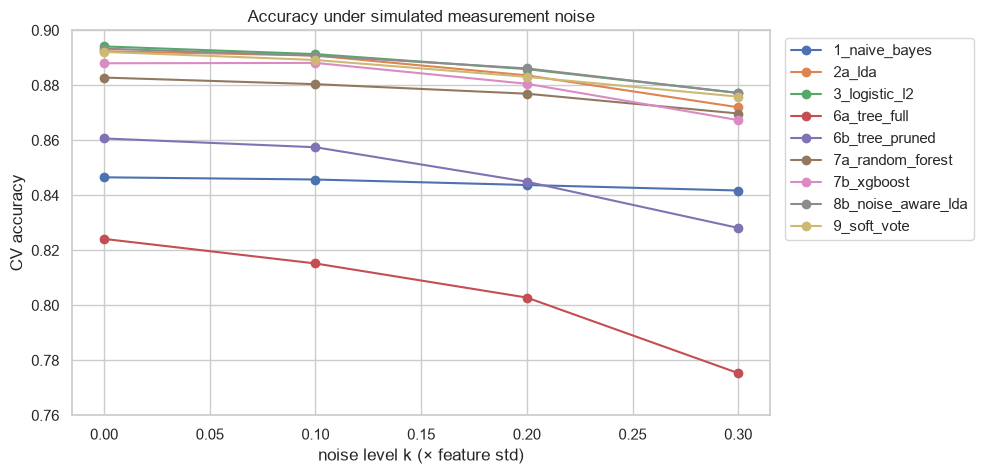

In [15]:
log = pd.read_csv(config.results_dir(TASK) / "experiments.csv")
cols = ["model", "params", "accuracy_mean", "accuracy_std", "train_accuracy_mean", "acc_k0.1", "acc_k0.2", "acc_k0.3", "acc_noise_mean", "public_lb"]
table = log[cols].sort_values("acc_noise_mean", ascending=False).reset_index(drop=True)
display(table.round(4))

main = ["1_naive_bayes", "2a_lda", "3_logistic_l2", "6a_tree_full", "6b_tree_pruned", "7a_random_forest", "7b_xgboost", "8b_noise_aware_lda", "9_soft_vote"]
ax = pd.DataFrame({m: curves[m] for m in main}).plot(marker="o", figsize=(9, 5))
ax.set(xlabel="noise level k (× feature std)", ylabel="CV accuracy", title="Accuracy under simulated measurement noise", ylim=(0.76, 0.9))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.savefig(FIG_DIR / "models_noise_curves.png", dpi=120, bbox_inches="tight")
plt.show()

## Submissions

In [16]:
best_name = table.model.iloc[0]
print("best by noise-averaged accuracy:", best_name)
candidates = {
    "3_logistic_l2": lambda: logistic(**lr_best),
    "4_logistic_l1": lambda: logistic(l1_best["C"], "l1"),
    "8a_logistic_noise_aug": lambda: NoiseAugmented(logistic(**lr_best), **aug_best),
    "8b_noise_aware_lda": lambda: NoiseAwareLDA(**nlda_best),
    "9_soft_vote": lambda: VotingClassifier([("logistic", logistic(**lr_best)), ("nlda", NoiseAwareLDA(**nlda_best)),
                                             ("forest", forest(**rf_best)), ("xgb", boost(**xgb_best))], voting="soft"),
    "2a_lda": lambda: LinearDiscriminantAnalysis(),
}
for name in dict.fromkeys([best_name, "8b_noise_aware_lda"]):
    path, sub = evaluate.make_submission(candidates[name](), X, y, X_test, test_ids, sample_sub, TASK, name, date="2026-10-12")
    print("saved:", path.name, "| predicted class shares:", sub.vehicle_class.value_counts(normalize=True).sort_index().round(3).to_dict())

best by noise-averaged accuracy: 8a_logistic_noise_aug


saved: 2026-10-12_8a_logistic_noise_aug.csv | predicted class shares: {0: 0.336, 1: 0.332, 2: 0.332}
saved: 2026-10-12_8b_noise_aware_lda.csv | predicted class shares: {0: 0.332, 1: 0.336, 2: 0.332}


- Public scores: 8b 0.902, 8a 0.900 (a tie). Both are selected for the private leaderboard.

## Summary
| Model | Clean CV | k = 0.3 | Noise-avg | Public |
|---|---|---|---|---|
| Naive Bayes | 0.847 | 0.842 | 0.844 | |
| LDA | 0.892 | 0.872 | 0.885 | |
| Logistic L2 (C = 0.1) | 0.894 | 0.877 | 0.887 | |
| Random Forest | 0.883 | 0.870 | 0.878 | |
| XGBoost | 0.888 | 0.867 | 0.881 | |
| **Logistic + noise augmentation** | **0.896** | 0.877 | **0.888** | 0.900 |
| **Noise-aware LDA** | 0.893 | 0.877 | 0.887 | **0.902** |